# TP 5 Geoloc 

Eléonore Veyron

## Echauffement : construire une URL

In [30]:
def url(num,typ,nom):
    return f"https://api-adresse.data.gouv.fr/search/?q={num}+{typ}+{nom},Paris&limit=1"
num = 3
typ = "rue"
nom = "tourelles"
print(url(num,typ,nom))

https://api-adresse.data.gouv.fr/search/?q=3+rue+tourelles,Paris&limit=1


## Echauffement : sélectionner des lignes avec iloc et loc


In [31]:

import pandas as pd

df = pd.DataFrame({
    "number": [3, 18, 7, 12, 5],
    "name": ["tourelles", "BERNARDINS", "Bouvart", "Rivoli", "Seine"],
})
sub = df[df.number > 10]

#1. sub devient df = pd.DataFrame({"number":[18,12],"name":["BERNARDINS","Rivoli"]})
# son index devient 1,3

#2. df.iloc[:2] = ({"number":[3,18],"name":["tourelles","BERNARDIN"]})
# df.loc[:2] = ({"number":[3,18,7],"name":["tourelles","BERNARDIN","Bouvart"]})
print(df.iloc[:2])
print(df.loc[:2])

#3. sub.iloc[:2] = ({"number":[18,12],"name":["BERNARDINS","Rivoli"]})
#sub.loc[:2] = ({"number":[18],"name":["BERNARDINS"]})

#4. sub.iloc[0] = 18, "BERNARDINS"
#sub.loc[0] = eror car pas d'index 0
print(sub.iloc[0])

#5. sub["name"].iloc[0] #on veut la 1ere ligne
#sub["name"].loc[1] #on regarde l'index
print(sub["name"].iloc[0])
print(sub["name"].loc[1]) # ou sub["name"].loc[sub.index[0]]


   number        name
0       3   tourelles
1      18  BERNARDINS
   number        name
0       3   tourelles
1      18  BERNARDINS
2       7     Bouvart
number            18
name      BERNARDINS
Name: 1, dtype: object
BERNARDINS
BERNARDINS


## Géolocalisation


In [32]:
import pandas as pd

addresses = pd.read_csv('ARTEFACTS-addresses-f6f90e822bcd81e4b53409289753e9ba/data/addresses.csv')
addresses.iloc[:21].to_csv("addresses-small.csv",index=False) #sauvegarde le fichier
# OU : addresses.head(20).to_csv("....", index=False) car on veut pas d'index
addresses.head(4) 



,number,type,name,city
0,5,rue,RIQUET,Paris
1,141,boulevard,ITALIE,Paris
2,234,rue,FAUBOURG ST-HONORÉ,Paris
3,62,rue,MICHEL BIZOT,Paris


## Une par une

a) on obtient un dictionnaire, c'est toute les rues tourelles de Paris

b) avec &limit=1 on obtient seulement les informations pour la 1ere rue de tourelles

c) c'est le 1er sous-dico


In [33]:

# requests is the swiss knife for doing http

import requests

def localize_one(num,typ,nom):
    url1 = url(num,typ,nom)
    r = requests.get(url1)
    if 200 <= r.status_code < 300: 
        return r.json()
    else : 
        return None 

import time

t1= time.time()
print(localize_one(18,'rue','BERNARDINS'))
t2= time.time()

print("Faire 30 000 requêtes prendrait", (t2-t1)*30000/3600, "h")
#c'est long car on importe tout le sous-dico

{'type': 'FeatureCollection', 'features': [{'type': 'Feature', 'geometry': {'type': 'Point', 'coordinates': [2.350728, 48.850345]}, 'properties': {'label': '18 Rue des Bernardins 75005 Paris', 'score': 0.7544495104895104, 'housenumber': '18', 'id': '75105_0896_00018', 'banId': 'acbebc10-eac0-475f-9466-e7dbe9446b02', 'name': '18 Rue des Bernardins', 'postcode': '75005', 'citycode': '75105', 'x': 652355.3, 'y': 6861340.65, 'city': 'Paris', 'district': 'Paris 5e Arrondissement', 'context': '75, Paris, Île-de-France', 'type': 'housenumber', 'importance': 0.68356, 'depcode': '75', 'street': 'Rue des Bernardins', '_type': 'address'}}], 'query': '18 rue BERNARDINS,Paris'}
Faire 30 000 requêtes prendrait 1.0563075542449951 h


## En un seul coup - en python

In [34]:


import requests

import io

def mass_post(filename, col_number, col_type, col_name, col_city):

    with open(filename) as feed:
        response = requests.post(
            "https://api-adresse.data.gouv.fr/search/csv/", 
            files={'data': feed},
            data={'columns': [col_number, col_type, col_name, col_city]})
    if not (200 <= response.status_code < 300):
        print(f"OOPS, got {response.status_code}")
        return None

    result = pd.read_csv(io.StringIO(response.text)) #car pd.read_csvp prend un dataframe

    return result


# votre code

def localize_many(filename, col_number, col_type, col_name, col_city):
    df = pd.read_csv(filename, encoding='utf-8')
    geoloc = mass_post(filename, col_number, col_type, col_name, col_city)
    geoloc = geoloc[['latitude', 'longitude', 'result_city', 'result_type']]
    return pd.merge(df,geoloc, how='left', on=df.index)

# try your code on the small sample for starters

addresses_small = localize_many("addresses-small.csv", "number", "type", "name", "city")
addresses_small = addresses_small[addresses_small['result_city']=='Paris']
addresses_small


,key_0,number,type,name,city,latitude,longitude,result_city,result_type
0,0,5,rue,RIQUET,Paris,48.888134,2.376448,Paris,housenumber
2,2,234,rue,FAUBOURG ST-HONORÉ,Paris,48.876160,2.302766,Paris,housenumber
3,3,62,rue,MICHEL BIZOT,Paris,48.835423,2.402040,Paris,housenumber
4,4,6,rue,OURS,Paris,48.863311,2.351775,Paris,housenumber
5,5,30,rue,PETIT-MUSC,Paris,48.852945,2.364722,Paris,housenumber
6,6,3,impasse,MASSONET,Paris,48.895498,2.351580,Paris,housenumber
7,7,56,rue,PANOYAUX,Paris,48.867023,2.388347,Paris,housenumber
8,8,16,rue,THÉRÈSE,Paris,48.866374,2.335212,Paris,housenumber
9,9,11,rue,JEAN ROBERT,Paris,48.889520,2.358170,Paris,housenumber
10,10,22,rue,FAUBOURG POISSONNIÈRE,Paris,48.872540,2.348002,Paris,housenumber


### Traitement par lots et le cache

In [35]:

import os 

if os.path.exists("localize_many.csv"):
    t1 = time.time()
    addresse2 = pd.read_csv("localize_many.csv")
    t2=time.time()
    print("Temps de l'opération",(t2-t1)/60,"min")
    
else: 
    t1=time.time()

    batch_size=1000

    initial = pd.read_csv("ARTEFACTS-addresses-f6f90e822bcd81e4b53409289753e9ba/data/addresses.csv", encoding='utf-8')
    a=initial.iloc[0:1000].to_csv("loc", index=False)
    addresse2= localize_many("loc", "number", "type", "name", "city")

    for i in range(1,20):
        a=initial.iloc[i:i+batch_size].to_csv("loc", index=False)
        addresse3 = localize_many("loc", "number", "type", "name", "city")
        addresse2= pd.concat([addresse2,addresse3], ignore_index=True)
        addresse2.to_csv("localize_many.csv",index=False) #sauvegarde le fichier

    t2=time.time()
    print("Temps de l'opération",(t2-t1)/60,"min")



addresse2

#os.remove pour supprimer les fichiers temporaires des lots

Temps de l'opération 0.0005462567011515299 min


,key_0,number,type,name,city,latitude,longitude,result_city,result_type
0,0,5,rue,RIQUET,Paris,48.888134,2.376448,Paris,housenumber
1,1,141,boulevard,ITALIE,Paris,46.669103,-1.418872,La Roche-sur-Yon,street
2,2,234,rue,FAUBOURG ST-HONORÉ,Paris,48.876160,2.302766,Paris,housenumber
3,3,62,rue,MICHEL BIZOT,Paris,48.835423,2.402040,Paris,housenumber
4,4,6,rue,OURS,Paris,48.863311,2.351775,Paris,housenumber
...,...,...,...,...,...,...,...,...,...
19995,995,229,boulevard,RASPAIL,Paris,48.839897,2.330662,Paris,housenumber
19996,996,3,rue,BAULANT,Paris,48.840910,2.386549,Paris,housenumber
19997,997,5,rue,GUYOT,Paris,48.891447,2.319708,Paris,housenumber
19998,998,23,rue,FAUBOURG SAINT-ANTOINE,Paris,48.852766,2.371394,Paris,housenumber


## Afficher sur une carte

In [36]:


import folium 

# ~ chatelet
CENTER = 48.856542, 2.347614

## Le fond de carte

In [37]:

# pour commencer on va recharger la dataframe précédente
import pandas as pd

addresses = pd.read_csv("ARTEFACTS-addresses-f6f90e822bcd81e4b53409289753e9ba/data/addresses-geoloc.csv")

# et en faire un petit échantillon
addresses_small = addresses.iloc[:20]

#Map centrée sur ce point et de zoom 13
def paris_map():
    return folium.Map(location= CENTER, zoom_start=13)
    
paris_map()

## On ajoute les adresses

In [38]:

addresses_small2 = addresses.iloc[:20]
addresses_small2.to_csv("adresses_small2.csv", index=False)


def map_addresses(geoloc):
    """
    creates folium map centered on Paris, with the various addresses
    contained in the input dataframe shown as a marker
    """
    m = paris_map()
    addresses_small2=geoloc.iloc[:20]
    location1=localize_many("adresses_small2.csv", "number", "type", "name", "city")
    for _, row in location1.iterrows():
        folium.Marker(
            location=(row["latitude_x"], row["longitude_x"]),
            tooltip="Click me!",
            icon=folium.Icon(icon="cloud"),
        ).add_to(m)
    return m

map_addresses(addresses)


## On sauve la carte 

In [39]:

map_small = map_addresses(addresses_small)
map_small.save("addresses-small.html")


## Les quartiers de Paris 

In [40]:
import geopandas as gpd

quartiers = gpd.read_file("ARTEFACTS-addresses-f6f90e822bcd81e4b53409289753e9ba/data/quartier_paris.zip", encoding="utf8")

type(quartiers)
quartiers

,n_sq_qu,c_qu,c_quinsee,l_qu,c_ar,n_sq_ar,perimetre,surface,st_area_sha,st_perimete,geometry
0,750000041,41,7511101,Folie-Méricourt,11,750000011,3724.352694,7.257525e+05,7.257525e+05,3724.205831,"POLYGON ((2.3701 48.86376, 2.3669 48.86246, 2...."
1,750000012,12,7510304,Sainte-Avoie,3,750000003,1861.804114,2.133164e+05,2.133164e+05,1861.724892,"POLYGON ((2.35822 48.86122, 2.3569 48.86007, 2..."
2,750000078,78,7512002,Saint-Fargeau,20,750000020,5405.036433,1.486971e+06,1.486971e+06,5404.838135,"POLYGON ((2.41381 48.87081, 2.41383 48.87066, ..."
3,750000060,60,7511504,Javel,15,750000015,8068.977385,2.609009e+06,2.609009e+06,8068.454983,"POLYGON ((2.28233 48.83495, 2.2839 48.83437, 2..."
4,750000062,62,7511602,Muette,16,750000016,11962.438594,5.477898e+06,5.477898e+06,11961.948852,"POLYGON ((2.24562 48.87636, 2.25482 48.87408, ..."
...,...,...,...,...,...,...,...,...,...,...,...
75,750000074,74,7511902,Pont-de-Flandre,19,750000019,6397.871676,2.376238e+06,2.376238e+06,6397.792841,"POLYGON ((2.38488 48.88663, 2.38483 48.88662, ..."
76,750000036,36,7510904,Rochechouart,9,750000009,2862.450525,5.004354e+05,5.004354e+05,2862.369078,"POLYGON ((2.34971 48.88222, 2.34983 48.88109, ..."
77,750000066,66,7511702,Plaine de Monceaux,17,750000017,5247.353247,1.383508e+06,1.383508e+06,5247.241240,"POLYGON ((2.3039 48.89006, 2.30403 48.89012, 2..."
78,750000073,73,7511901,Villette,19,750000019,5191.018830,1.285705e+06,1.285705e+06,5190.901965,"POLYGON ((2.3705 48.8782, 2.37028 48.87799, 2...."


<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

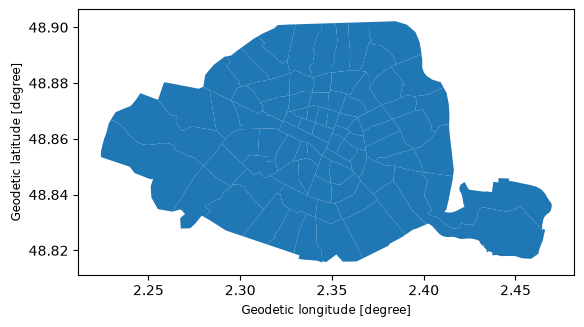

In [41]:
quartiers.plot()

In [42]:
def paris_map():
    """
    create a map of Paris with its 80 quartiers
    """
    map = folium.Map(
        location=CENTER,
        zoom_start=13,
        # width='80%',
    )

    folium.GeoJson(
        data=quartiers,
    ).add_to(map)

    return map


paris_map()


## Un peu de couleurs

In [43]:
#1. 



# J'avais commencé à répondre aux questions 
#avant de suivre les indications 
#voir plus bas (autres cellules) pour les fonctions
#avec la logique demandée




import random 

def random_color():
    """
    retourne une couleur au hasard du type #......
    """
    lettre = ["a","b","c","d","e","f"]
    nb = [i for i in range(10)] + lettre 
    couleur = "#"
    for i in range(6):
        a = random.choice(nb)
        if a in lettre: #pour l'ajout à couleur
            couleur = couleur + a
        else : 
            couleur = couleur + f"{a}" #transformation du int en str
    return couleur 

print(random_color())

#2  Ajout d'une colonne à "quartiers"

quartiers["couleur"]=[random_color() for i in range(quartiers.shape[0])]

#3. NE MARCHE PAS

#def map_addresses_in_quartiers_2():
   # map = folium.Map(
    #    location=CENTER,
    #    zoom_start=13,
    #    # width='80%',
    #)

    #folium.GeoJson(
    #    data=quartiers,
    #    style_function= lambda feature :{"fillcolor": quartiers["couleurs"]}   
    #).add_to(map)
#    return map



#114ada


### Echauffement : le formatage hexadécimal

In [44]:
# 1. 
#  f"{x:02x}" donne pour x = 255 : ff et pour x = 3: 03

#2. Le 2 signifie qu'on aura 2 chiffres en sortie et 0 
# complété par 0 à gauche (x minuscule précise si lettre écrit en min)

# il suffit de choisir trois nombre x compris entre 0 et 25 aléatoirement 
# et les additionné en terme de str

Couleurs : étape 1

In [45]:
def random_color():
    x,y,z = random.randint(0, 255),random.randint(0, 255),random.randint(0, 255)
    return "#"+f"{x:02x}" + f"{y:02x}" + f"{z:02x}"

random_color()

'#31ef4c'

Couleurs : étape 2

#déjà fait dans la cellule "Un peu de couleurs" ;
colonne appelée "couleurs"

In [46]:
quartiers.head(3)

,n_sq_qu,c_qu,c_quinsee,l_qu,c_ar,n_sq_ar,perimetre,surface,st_area_sha,st_perimete,geometry,couleur
0,750000041,41,7511101,Folie-Méricourt,11,750000011,3724.352694,7.257525e+05,7.257525e+05,3724.205831,"POLYGON ((2.3701 48.86376, 2.3669 48.86246, 2....",#e48b93
1,750000012,12,7510304,Sainte-Avoie,3,750000003,1861.804114,2.133164e+05,2.133164e+05,1861.724892,"POLYGON ((2.35822 48.86122, 2.3569 48.86007, 2...",#b8a69f
2,750000078,78,7512002,Saint-Fargeau,20,750000020,5405.036433,1.486971e+06,1.486971e+06,5404.838135,"POLYGON ((2.41381 48.87081, 2.41383 48.87066, ...",#bb480a


Couleurs : étape 3

In [47]:

def map_addresses_in_quartiers_2():
    map = folium.Map(
        location=CENTER,
        zoom_start=13,
        width='80%',
        titles = 'Quartiers de Paris coloriés'
    )

    folium.GeoJson(
        data=quartiers,
        style_function= lambda feature: {
            "fillColor": feature['properties']['couleur'],
            "fillOpacity":0.5
            }   
    ).add_to(map)
    
    
    return map
map_addresses_in_quartiers_2()


## Spatial join 

Etape 1

In [48]:
def convert_lat_lon(df):
    """
    the input df is expected to have 2 columns named 'latitude' and 'longitude'

    this function will create a GeoDataFrame based on that, where 'latitude' and 'longitude'
    are replaced by a new column named 'position' 
    also this new column becomes the active geometry for future operations 
    (in our case the spatial join)
    """

    # we need a geopandas-friendly df
    geo_df = gpd.GeoDataFrame(df)

    # beware, here LONGITUDE comes first !
    geo_df['position'] = gpd.points_from_xy(df.longitude, df.latitude)

    # it would make sense to clean up
    # BUT
    # our map-production code relies on these columns, so...
    # del geo_df['latitude']
    # del geo_df['longitude']

    # declare the new column as the active one
    geo_df.set_geometry('position', inplace=True)

    return geo_df


In [49]:
# let's apply that to our small input

geoaddresses_small = convert_lat_lon(addresses_small)

geoaddresses_small.head(3)

,number,type,name,city,latitude,longitude,result_city,result_type,position
0,5,rue,RIQUET,Paris,48.888134,2.376448,Paris,housenumber,POINT (2.37645 48.88813)
1,141,boulevard,ITALIE,Paris,48.820646,2.359275,Paris,housenumber,POINT (2.35928 48.82065)
2,234,rue,FAUBOURG ST-HONORÉ,Paris,48.876160,2.302766,Paris,housenumber,POINT (2.30277 48.87616)


In [50]:
# we will also need to set the active column in the quartiers (geo)dataframe

quartiers.set_geometry('geometry', inplace=True)

quartiers.head(3)

,n_sq_qu,c_qu,c_quinsee,l_qu,c_ar,n_sq_ar,perimetre,surface,st_area_sha,st_perimete,geometry,couleur
0,750000041,41,7511101,Folie-Méricourt,11,750000011,3724.352694,7.257525e+05,7.257525e+05,3724.205831,"POLYGON ((2.3701 48.86376, 2.3669 48.86246, 2....",#e48b93
1,750000012,12,7510304,Sainte-Avoie,3,750000003,1861.804114,2.133164e+05,2.133164e+05,1861.724892,"POLYGON ((2.35822 48.86122, 2.3569 48.86007, 2...",#b8a69f
2,750000078,78,7512002,Saint-Fargeau,20,750000020,5405.036433,1.486971e+06,1.486971e+06,5404.838135,"POLYGON ((2.41381 48.87081, 2.41383 48.87066, ...",#bb480a


Etape 2

In [51]:
def add_quartiers(gdf):
    """
    given an addresses geo-dataframe, 
    (i.e. typically produced as an output of convert_lat_lon)
    this function will use spatial join with the quartiers information
    and return a copy of gdf extended with columns such as
    l_qu : name of the quartier
    c_ar : arrondissement number
    color: the (random) color of that quartier
    ...

    """
    quartiers_reduit= quartiers[['l_qu','c_ar','couleur','geometry']]
    gdf_result = gdf.sjoin(quartiers_reduit, how="left", predicate="within")

    return gdf_result

print(geoaddresses_small.head(3))
add_quartiers(geoaddresses_small)

   number       type                name   city   latitude  longitude  \
0       5        rue              RIQUET  Paris  48.888134   2.376448   
1     141  boulevard              ITALIE  Paris  48.820646   2.359275   
2     234        rue  FAUBOURG ST-HONORÉ  Paris  48.876160   2.302766   

  result_city  result_type                  position  
0       Paris  housenumber  POINT (2.37645 48.88813)  
1       Paris  housenumber  POINT (2.35928 48.82065)  
2       Paris  housenumber  POINT (2.30277 48.87616)  


c:\miniconda\Lib\site-packages\geopandas\geodataframe.py:2680: UserWarning: CRS mismatch between the CRS of left geometries and the CRS of right geometries.
Use `to_crs()` to reproject one of the input geometries to match the CRS of the other.

Left CRS: None
Right CRS: EPSG:4326

  return geopandas.sjoin(


,number,type,name,city,latitude,longitude,result_city,result_type,position,index_right,l_qu,c_ar,couleur
0,5,rue,RIQUET,Paris,48.888134,2.376448,Paris,housenumber,POINT (2.37645 48.88813),78,Villette,19,#db89f4
1,141,boulevard,ITALIE,Paris,48.820646,2.359275,Paris,housenumber,POINT (2.35928 48.82065),14,Maison-Blanche,13,#b77a40
2,234,rue,FAUBOURG ST-HONORÉ,Paris,48.876160,2.302766,Paris,housenumber,POINT (2.30277 48.87616),47,Faubourg-du-Roule,8,#b2221d
3,62,rue,MICHEL BIZOT,Paris,48.835423,2.402040,Paris,housenumber,POINT (2.40204 48.83542),44,Picpus,12,#859845
4,6,rue,OURS,Paris,48.863311,2.351775,Paris,housenumber,POINT (2.35178 48.86331),1,Sainte-Avoie,3,#b8a69f
5,30,rue,PETIT-MUSC,Paris,48.852945,2.364722,Paris,housenumber,POINT (2.36472 48.85294),61,Arsenal,4,#46178f
6,3,impasse,MASSONET,Paris,48.895498,2.351580,Paris,housenumber,POINT (2.35158 48.8955),62,Clignancourt,18,#f53c05
7,56,rue,PANOYAUX,Paris,48.867023,2.388347,Paris,housenumber,POINT (2.38835 48.86702),35,Père-Lachaise,20,#dfc5a0
8,16,rue,THÉRÈSE,Paris,48.866374,2.335212,Paris,housenumber,POINT (2.33521 48.86637),79,Palais-Royal,1,#2e12ef
9,11,rue,JEAN ROBERT,Paris,48.889520,2.358170,Paris,housenumber,POINT (2.35817 48.88952),51,Goutte-d'Or,18,#9239f8


In [ ]:

geoaddresses_small_extended = add_quartiers(geoaddresses_small)
geoaddresses_small_extended.head(2)


,number,type,name,city,latitude,longitude,result_city,result_type,position,index_right,l_qu,c_ar,couleur
0,5,rue,RIQUET,Paris,48.888134,2.376448,Paris,housenumber,POINT (2.37645 48.88813),78,Villette,19,#db89f4
1,141,boulevard,ITALIE,Paris,48.820646,2.359275,Paris,housenumber,POINT (2.35928 48.82065),14,Maison-Blanche,13,#b77a40


In [82]:

geoaddresses_small_extended.shape

(20, 13)

Etape 3

In [ ]:

def map_addresses3(gdf):
    """
    (slightly) rewrite the first version of this function

    your input is now a geopandas dataframe, with the information
    about the 'quartier'

    and your job is to display all the addresses on the map, now with
    the color of the 'quartier'

    return a folium map of paris with the adresses displayed
    """
    m = paris_map()
    
    for _, row in gdf.iterrows():
        folium.CircleMarker(
            location=(row["latitude"], row["longitude"]),
            tooltip=row.get("l_qu","Adresse"),
            radius=5,
            color = row['couleur'],
            fill = True,
            fill_color = row['couleur']
        ).add_to(m)
    
    return m


In [88]:
# test the new function

map3 = map_addresses3(geoaddresses_small_extended)

map3

### On sauve la carte

In [90]:
geoaddresses_small_extended.to_csv("addresses-small-extended.csv")

map3.save("addresses3-localisees.html")


### On clusterise

In [94]:
from folium import plugins

def map_addresses(gdf):

    # start like before
    if 'human' not in gdf.columns:
        # create a column with a human-readable address
        gdf['human'] = gdf['number'].astype(str) + ', ' + gdf['type'] + ' ' + gdf['name']

    map = paris_map()


    # we need a JavaScript function...
    # this is required to get  good performances
    callback = """
function (row) {
  // if you need to debug it
  // console.log(row)
  let circle = L.circleMarker(
      // the position
      new L.LatLng(row[0], row[1]),
      // styling
     {color: row[3], radius: 8},
    )
  // add the tooltip
  circle.bindTooltip(row[2]).openTooltip()
  return circle
}
"""

    # compute an extract with fewer columns
    # not strictly necessary but easier to deal with column names
    extract = gdf[['latitude', 'longitude', 'human', 'couleur']]
    cluster = plugins.FastMarkerCluster(
        extract, callback=callback,
        # nicer behaviour
        disableClusteringAtZoom=18,
    ).add_to(map)

    return map


In [95]:
# let's first test it on the small extract

map_addresses(geoaddresses_small_extended)


In [96]:


geoaddresses = add_quartiers(convert_lat_lon(addresses))
final_map = map_addresses(geoaddresses)

final_map


c:\miniconda\Lib\site-packages\geopandas\geodataframe.py:2680: UserWarning: CRS mismatch between the CRS of left geometries and the CRS of right geometries.
Use `to_crs()` to reproject one of the input geometries to match the CRS of the other.

Left CRS: None
Right CRS: EPSG:4326

  return geopandas.sjoin(
